# Возрастная динамика вопросительных реплик в RusLan-M

**Исследовательский вопрос.** Как меняется доля вопросительно оформленных реплик в речи Тоси, Яши и взрослых из их записей по мере взросления ребёнка?

**Теоретическая основа.** Yu, Bonawitz & Shafto вручную различали педагогические, информационные и риторические вопросы родителей. В их выборке общая частота вопросов родителей не показала статистически значимой связи с возрастом. Среди самих вопросов с возрастом снижалась доля педагогических и росла доля информационных. В первом случае знаменатель — все реплики, во втором — только вопросы. В этом проекте изучаем первый показатель и добавляем речь целевых детей. Сравнение со статьёй качественное: там изучались англоязычные разговоры родителей с детьми 2–6 лет, здесь — две русскоязычные лонгитюдные серии с другим составом взрослых и более ранними возрастами.

**Источники.** Задание взято из приложенного «нис_проект.pdf», где сформулирован исследовательский вопрос и предложены полугодовые интервалы. Анализируем приложенный архив `RusLan.zip`. [Yu et al., *Child Development*, 2019 (онлайн в 2017)](https://doi.org/10.1111/cdev.12850) · [RusLan, CHILDES/TalkBank](https://doi.org/10.21415/1XMG-D508).

**Запуск.** Положите `RusLan.zip` рядом с ноутбуком и выполните **Restart Kernel and Run All**. В окружении нужны Python 3.10+, pandas, NumPy, Matplotlib и IPython. При необходимости установите библиотеки в ячейке Jupyter: `%pip install pandas numpy matplotlib`. Результаты последнего прогона уже сохранены в ноутбуке.

## 1. Подготовка и входные данные

`Path` находит архив, `ZipFile` читает данные прямо из него, а SHA-256 фиксирует конкретную версию входного файла. Приоритет у архива рядом с ноутбуком. В облачном сеансе предусмотрен запасной поиск среди исходных вложений. `testzip()` проверяет целостность всех членов архива.

In [1]:
from hashlib import sha256
from pathlib import Path, PurePosixPath
import re
from zipfile import ZipFile

from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

archive_path = Path("RusLan.zip")
if not archive_path.is_file():
    cloud_attachments = sorted(Path("/workspace/attachments").glob("*/RusLan.zip"))
    if len(cloud_attachments) != 1:
        raise FileNotFoundError("Положите RusLan.zip рядом с ноутбуком.")
    archive_path = cloud_attachments[0]

with ZipFile(archive_path) as archive:
    bad_member = archive.testzip()
    assert bad_member is None, f"Повреждённый член архива: {bad_member}"
print(f"Архив: {archive_path.name}")
print(f"SHA-256: {sha256(archive_path.read_bytes()).hexdigest()}")
print(f"pandas {pd.__version__}, NumPy {np.__version__}")

Архив: RusLan.zip
SHA-256: f96bb0d107acd747694e167659388bd1743d8c4cb8128dd09ea26536c94d5c62
pandas 2.2.3, NumPy 2.3.5


## 2. Как CHAT превращается в таблицу

Заголовок `@ID:` содержит код участника, возраст и роль. Возраст берём у участника с ролью `Target_Child` в том же файле. Код роли читается для каждого файла заново, поэтому Тося учитывается как `CHI1` в записи, где сестра обозначена `CHI2`.

`read_utterances()` выделяет основные реплики `*КОД:` и присоединяет строки-продолжения. Слои `%mor` и `%gra` содержат разметку и не создают новых реплик. Функция сохраняет номер строки для проверки по оригиналу. `clean_text()` убирает скрытые медиа-метки CHAT; `question_flags()` отмечает знак `?` за пределами квадратных скобок CHAT. В основной подсчёт входит и `+/?`, обозначающий прерванную вопросительную реплику. Каждая реплика даёт максимум один вопрос.

In [2]:
MAIN_TIER = re.compile(r"^\*([A-Za-z0-9_]+):\s*(.*)$")
MEDIA_MARK = re.compile(r"\x15[^\x15]*\x15")
BRACKET_ANNOTATION = re.compile(r"\[[^\[\]]*\]")
AGE_PATTERN = re.compile(r"(\d+);(\d{2})\.(\d{2})")


def age_components(age):
    match = AGE_PATTERN.fullmatch(age)
    if match is None:
        raise ValueError(f"Неизвестный формат возраста: {age!r}")
    years, months, days = map(int, match.groups())
    assert 0 <= months < 12 and 0 <= days <= 31, age
    return 12 * years + months, days


def read_participants(lines):
    participants = {}
    for line in lines:
        if line.startswith("@ID:"):
            fields = line.partition(":")[2].strip().split("|")
            code, age, role = (fields[index].strip() for index in (2, 3, 7))
            assert code not in participants, f"Дублирующийся @ID: {code}"
            participants[code] = {"age": age, "role": role}
    return participants


def read_utterances(lines):
    rows = []
    on_main_tier = False
    for number, line in enumerate(lines, start=1):
        match = MAIN_TIER.fullmatch(line)
        if match:
            speaker, text = match.groups()
            rows.append({"line": number, "speaker": speaker, "raw": text})
            on_main_tier = True
        elif line.startswith(("\t", " ")) and on_main_tier:
            rows[-1]["raw"] += " " + line.strip()
        else:
            on_main_tier = False
            assert not line.startswith("*"), f"Не распознана реплика {number}: {line}"
    return rows


def clean_text(raw):
    return MEDIA_MARK.sub("", raw).strip()


def question_flags(text):
    speech = BRACKET_ANNOTATION.sub("", text).strip()
    marked = "?" in speech
    plain_final = speech.endswith("?") and not speech.endswith("+/?")
    return marked, plain_final

### Проверка парсера на маленьком примере

`assert` сразу останавливает выполнение, если парсер склеил чужой слой, потерял продолжение реплики или неправильно обработал пунктуацию. Здесь также проверяем переход на границе месяца и код целевого ребёнка, отличный от `CHI`.

In [3]:
toy_lines = [
    "@ID:\trus|RusLan|CHI1|1;03.29|female|||Target_Child|||",
    "*CHI1:\tа",
    "\tкто там ? \x1510_20\x15",
    "%mor:\tчто-то ?",
    "\tпродолжение служебного слоя ?",
    "*MOT:\tкукла [= неясно?] .",
    "*CHI1:\tа +/?",
]
toy_rows = read_utterances(toy_lines)
assert len(toy_rows) == 3
assert toy_rows[0]["line"] == 2
assert clean_text(toy_rows[0]["raw"]) == "а кто там ?"
assert [question_flags(clean_text(row["raw"])) for row in toy_rows] == [
    (True, True), (False, False), (True, False),
]
assert read_participants(toy_lines)["CHI1"]["role"] == "Target_Child"
assert age_components("1;03.29") == (15, 29)
assert age_components("1;04.00") == (16, 0)
print("Проверки парсера, пунктуации и возраста пройдены.")

Проверки парсера, пунктуации и возраста пройдены.


## 3. Возраст, говорящие и объём архива

Для главного анализа группа **«взрослый»** определяется по явным ролям взрослого, включая родителей, бабушек, дедушек, няню и опекуна. Группа **«ребёнок»** включает только `Target_Child`. Сёстры, братья и другие детские роли идут в отдельную группу. Коды `TOY` и `SIN` исключены из основного сравнения как «прочие». Для `Female` и `Relative` возраст не указан, поэтому они учитываются как неопределённые. Проверим, меняется ли вывод, если включить их в категорию взрослых.

Цикл читает все `.cha`, собирая две таблицы. `files` содержит по строке на файл для контроля заголовков и возраста. `utterances` содержит по строке на основную реплику. Поле `placeholder` отмечает реплики, состоящие только из условных обозначений типа `xxx` или `www` и пунктуации. В основном знаменателе они остаются как строки транскрипции.

In [4]:
SERIES = {"Tosya": "Тося", "Yasha": "Яша"}
ADULT_ROLES = {
    "Adult", "Mother", "Father", "Grandmother", "Grandfather", "Nurse", "Caretaker",
}
OTHER_CHILD_ROLES = {"Child", "Sister", "Brother", "Girl", "Boy"}
UNCERTAIN_ROLES = {"Female", "Relative"}
PARENT_ROLES = {"Mother", "Father"}
OTHER_ROLES = {"Other"}
PLACEHOLDER = re.compile(
    r"(?:xxx|yyy|www|0)(?:\s+(?:xxx|yyy|www|0))*\s*(?:[.!?]|\+[./!?]+)?",
    flags=re.IGNORECASE,
)


def speaker_group(role):
    if role == "Target_Child":
        return "ребёнок"
    if role in ADULT_ROLES:
        return "взрослый"
    if role in OTHER_CHILD_ROLES:
        return "другой ребёнок"
    if role in UNCERTAIN_ROLES:
        return "неопределённый"
    if role in OTHER_ROLES:
        return "прочий"
    raise ValueError(f"Новая роль в архиве: {role!r}")


def transcript_order(name):
    path = PurePosixPath(name)
    file_number = int(re.search(r"\d+$", path.stem)[0])
    return path.parent.name, file_number


file_rows = []
utterance_rows = []
independent_line_count = 0
with ZipFile(archive_path) as archive:
    transcripts = sorted(
        (name for name in archive.namelist() if name.endswith(".cha")),
        key=transcript_order,
    )
    assert len(transcripts) == len(set(transcripts)), "В архиве повторяются пути."
    age_lists = {
        label: [int(age) for age in archive.read(f"{folder}-ages.txt").split()]
        for folder, label in SERIES.items()
    }
    for name in transcripts:
        folder, number = transcript_order(name)
        child = SERIES[folder]
        lines = archive.read(name).decode("utf-8-sig").splitlines()
        independent_line_count += sum(line.startswith("*") for line in lines)
        participants = read_participants(lines)
        targets = [code for code, meta in participants.items() if meta["role"] == "Target_Child"]
        assert len(targets) <= 1, f"Несколько целевых детей в {name}"
        target = targets[0] if targets else None
        age = participants[target]["age"] if target else ""
        month, day = age_components(age) if age else (None, None)
        file_rows.append({
            "file": name, "file_number": number, "child": child, "target": target,
            "age": age, "months": month, "days": day,
            "date": next((line.partition(":")[2].strip() for line in lines
                          if line.startswith("@Date:")), ""),
            "other_ages": ", ".join(f"{code}: {meta['age']}" for code, meta in participants.items()
                                    if code != target and meta["age"]),
        })
        for row in read_utterances(lines):
            assert row["speaker"] in participants, (name, row["line"], row["speaker"])
            role = participants[row["speaker"]]["role"]
            text = clean_text(row["raw"])
            question, plain_final = question_flags(text)
            utterance_rows.append({
                "file": name, "line": row["line"], "speaker": row["speaker"],
                "role": role, "group": speaker_group(role), "text": text,
                "question": question, "plain_final": plain_final,
                "placeholder": bool(PLACEHOLDER.fullmatch(text)),
            })

files = pd.DataFrame(file_rows)
utterances = pd.DataFrame(utterance_rows).merge(
    files[["file", "child", "age", "months", "days"]], on="file", validate="many_to_one",
)

### Контроль чтения и возраста

Сверяем число реплик с независимым подсчётом строк, начинающихся со звёздочки. Отдельно проверяем, что число файлов совпадает с архивом и что `(файл, строка)` однозначно идентифицирует реплику. Списки возрастов сверяем с последовательностью **заполненных** заголовков в порядке номера записи. Приведение к целому убирает ведущие нули; соответствие восстанавливать по позиции для файлов без возраста нельзя.

In [5]:
assert len(files) == len(transcripts)
assert len(utterances) == independent_line_count
assert not utterances.duplicated(["file", "line"]).any()
assert set(files["file"]) == set(utterances["file"])
assert utterances.loc[utterances["plain_final"], "question"].all()

for child, ages in age_lists.items():
    observed = files.loc[(files["child"] == child) & files["months"].notna(), "age"]
    header_values = [int(age.replace(";", "").replace(".", "")) for age in observed]
    assert ages == header_values, f"Расхождение заголовков и списка возрастов: {child}"

file_inventory = files.groupby("child", sort=False).agg(
    files=("file", "size"), with_age=("months", "count"),
)
display(file_inventory.rename(columns={"files": "Файлов", "with_age": "С возрастом"}))
display(files.loc[files["months"].isna(), ["file", "target", "date", "other_ages"]]
        .merge(utterances.groupby("file").size().rename("Реплик"), on="file")
        .rename(columns={"file": "Файл", "target": "Код ребёнка",
                         "date": "Дата в CHAT", "other_ages": "Возраст в других @ID"})
        .reset_index(drop=True))
print(f"Проверено: {len(utterances):,} основных реплик и {len(files)} транскрипций.")

,Файлов,С возрастом
child,,
Тося,246,242
Яша,42,42


,Файл,Код ребёнка,Дата в CHAT,Возраст в других @ID,Реплик
0,Tosya/T6.cha,None,19-SEP-2016,,14
1,Tosya/T17.cha,None,19-SEP-2016,,7
2,Tosya/T101.cha,CHI,26-JUN-2017,GRA: 1;09.29,253
3,Tosya/T202.cha,CHI,,NAN: 2;06.18,600


Проверено: 78,239 основных реплик и 288 транскрипций.


### Почему знаменатель отличается от числа в задании

Таблица показывает все основные реплики по группам во вложенном архиве **до отбора по возрасту**. Затем сравниваем числа с теми, что приведены на скриншоте в задании. Отдельно считаем наивный вариант «все кроме целевого ребёнка»: он нужен, чтобы показать, почему дополнение к детской выборке нельзя напрямую назвать взрослой речью.

In [6]:
inventory = pd.crosstab(utterances["child"], utterances["group"]).reindex(SERIES.values())
inventory["все реплики"] = inventory.sum(axis=1)
display(inventory)

reference = pd.DataFrame({
    "Взрослые в задании": [40_811, 12_278],
    "Дети в задании": [21_421, 13_965],
}, index=list(SERIES.values()))
volume_check = reference.assign(
    **{
        "Взрослые в ZIP": inventory["взрослый"],
        "Целевой ребёнок в ZIP": inventory["ребёнок"],
        "Все кроме целевого ребёнка": inventory["все реплики"] - inventory["ребёнок"],
    },
)
display(volume_check)
print(f"Строго определённые взрослые в ZIP: {inventory['взрослый'].sum():,}.")
print(f"В задании: {reference['Взрослые в задании'].sum():,}.")
print(f"Все реплики вне целевого ребёнка в ZIP: "
      f"{volume_check['Все кроме целевого ребёнка'].sum():,}.")

group,взрослый,другой ребёнок,неопределённый,прочий,ребёнок,все реплики
child,,,,,,
Тося,34461,1413,78,101,16599,52652
Яша,8089,3824,14,48,13612,25587


,Взрослые в задании,Дети в задании,Взрослые в ZIP,Целевой ребёнок в ZIP,Все кроме целевого ребёнка
Тося,40811,21421,34461,16599,36053
Яша,12278,13965,8089,13612,11975


Строго определённые взрослые в ZIP: 42,550.
В задании: 53,089.
Все реплики вне целевого ребёнка в ZIP: 48,028.


## 4. Ручная сверка с оригиналом

Примеры выбраны намеренно для проверки пограничных случаев; по ним нельзя оценить точность на всём корпусе. Ожидаемые метки заданы по видимым строкам CHAT, затем `merge` подставляет результаты парсера, а `assert` сравнивает обе колонки. Пример с родителем, няней или другим взрослым показывает только вопросительную форму. Адресата и коммуникативную функцию из одной реплики установить не всегда возможно.

In [7]:
manual = pd.DataFrame([
    ("Tosya/T1.cha", 13, "взрослый", True, "Вопрос няни; адресат неоднозначен."),
    ("Tosya/T1.cha", 24, "взрослый", True, "Скобки с исправлением слова."),
    ("Tosya/T1.cha", 30, "взрослый", False, "Ответ с точкой."),
    ("Tosya/T7.cha", 13, "другой ребёнок", True, "CHI2 — сестра."),
    ("Tosya/T7.cha", 39, "ребёнок", False, "CHI1 — Тося."),
    ("Tosya/T26.cha", 54, "взрослый", True, "Прерванный вопрос +/?."),
    ("Tosya/T246.cha", 20, "ребёнок", True, "Вопрос Тоси."),
    ("Yasha/Ya1.cha", 16, "ребёнок", False, "Детская вокализация с точкой."),
    ("Yasha/Ya1.cha", 19, "взрослый", True, "Вопрос отца."),
    ("Yasha/Ya1.cha", 34, "прочий", False, "Код TOY."),
    ("Yasha/Ya23.cha", 38, "ребёнок", True, "Вопрос Яши."),
    ("Yasha/Ya23.cha", 1221, "неопределённый", False,
     "По смыслу возможен вопрос, но в CHAT стоит точка."),
], columns=["file", "line", "expected_group", "expected_question", "Комментарий"])
audit = manual.merge(
    utterances[["file", "line", "speaker", "group", "question", "text"]],
    on=["file", "line"], how="left", validate="one_to_one",
)
assert audit["group"].eq(audit["expected_group"]).all()
assert audit["question"].eq(audit["expected_question"]).all()
display(audit[["file", "line", "speaker", "text", "group", "question", "Комментарий"]]
        .rename(columns={"file": "Файл", "line": "Строка", "speaker": "Код",
                         "text": "Реплика", "group": "Группа", "question": "Вопрос"}))
print(f"Ручная сверка: {len(audit)} из {len(audit)} примеров совпали.")

,Файл,Строка,Код,Реплика,Группа,Вопрос,Комментарий
0,Tosya/T1.cha,13,NAN,"мама , можно , мам ?",взрослый,True,Вопрос няни; адресат неоднозначен.
1,Tosya/T1.cha,24,MOT,"ну чё [: что] , будем играть , котики ?",взрослый,True,Скобки с исправлением слова.
2,Tosya/T1.cha,30,MOT,конечно .,взрослый,False,Ответ с точкой.
3,Tosya/T7.cha,13,CHI2,есть что-нибудь съйестное@u ?,другой ребёнок,True,CHI2 — сестра.
4,Tosya/T7.cha,39,CHI1,ммм .,ребёнок,False,CHI1 — Тося.
5,Tosya/T26.cha,54,NAN,а что бы [: было] +/?,взрослый,True,Прерванный вопрос +/?.
6,Tosya/T246.cha,20,CHI,"+, про Курочку Рябу ?",ребёнок,True,Вопрос Тоси.
7,Yasha/Ya1.cha,16,CHI,э@u .,ребёнок,False,Детская вокализация с точкой.
8,Yasha/Ya1.cha,19,FAT,"покажи , где корова ?",взрослый,True,Вопрос отца.
9,Yasha/Ya1.cha,34,TOY,му@o .,прочий,False,Код TOY.


Ручная сверка: 12 из 12 примеров совпали.


## 5. Доли по полугодиям

Возраст выражаем в полных месяцах. `assign_periods()` вычисляет начало интервала из возраста и начальной границы. Например, 15 месяцев 29 дней попадают в `[10, 16)`, а ровно 16 месяцев — в `[16, 22)`. Используем непересекающиеся интервалы по шесть месяцев, начиная с 10 месяцев для Тоси и с 17 месяцев для Яши. Ровно 46 месяцев у Тоси открывают седьмой интервал. Последние интервалы обеих серий наблюдаются частично.

`summarize_periods()` отдельно для каждого ребёнка и каждой группы считает число файлов, число реплик и число вопросительно оформленных реплик. Доля равна `100 × вопросы / все реплики`. `diff()` даёт изменение от предыдущего наблюдаемого полугодия в процентных пунктах (п. п.). Полугодие с отсутствующей группой получило бы пропуск. Общий результат вычисляем по сумме реплик, поэтому файл с большим количеством реплик влияет сильнее.

In [8]:
MAIN_GROUPS = ["взрослый", "ребёнок"]
ANCHORS = {"Тося": 10, "Яша": 17}
HALF_YEAR = 6


def assign_periods(data, anchors):
    anchors_by_child = data["child"].map(anchors)
    starts = anchors_by_child + HALF_YEAR * ((data["months"] - anchors_by_child) // HALF_YEAR)
    return data.assign(start=starts.astype(int))


def summarize_periods(data, anchors=ANCHORS, flag="question"):
    periods = assign_periods(data, anchors)
    result = periods.groupby(["child", "start", "group"], as_index=False).agg(
        files=("file", "nunique"), total=("line", "size"), questions=(flag, "sum"),
    )
    result["pct"] = 100 * result["questions"] / result["total"]
    result["interval"] = result["start"].map(lambda start: f"[{start}, {start + HALF_YEAR})")
    result["change_pp"] = result.groupby(["child", "group"])["pct"].diff()
    return result


eligible = utterances.loc[
    utterances["months"].notna() & utterances["group"].isin(MAIN_GROUPS)
].copy()
periods = summarize_periods(eligible)

boundary_test = pd.DataFrame({"child": ["Тося"] * 4, "months": [15, 16, 45, 46]})
assert assign_periods(boundary_test, ANCHORS)["start"].tolist() == [10, 16, 40, 46]
assert periods["total"].sum() == len(eligible)
assert periods["questions"].sum() == eligible["question"].sum()
assert periods["questions"].le(periods["total"]).all()
assert periods["pct"].between(0, 100).all()

TABLE_LABELS = {
    "child": "Серия", "interval": "Возраст, мес.", "group": "Группа",
    "files": "Файлов с репликами группы", "total": "Реплик",
    "questions": "Вопросительных", "pct": "Доля, %",
    "change_pp": "Δ к предыдущему, п. п.",
}
show_columns = ["child", "interval", "group", "files", "total", "questions", "pct", "change_pp"]
display(periods[show_columns].round(2).rename(columns=TABLE_LABELS))

,Серия,"Возраст, мес.",Группа,Файлов с репликами группы,Реплик,Вопросительных,"Доля, %","Δ к предыдущему, п. п."
0,Тося,"[10, 16)",взрослый,46,6533,1570,24.03,NaN
1,Тося,"[10, 16)",ребёнок,46,1623,6,0.37,NaN
2,Тося,"[16, 22)",взрослый,53,7716,1934,25.06,1.03
3,Тося,"[16, 22)",ребёнок,53,2896,19,0.66,0.29
4,Тося,"[22, 28)",взрослый,76,12321,3460,28.08,3.02
5,Тося,"[22, 28)",ребёнок,76,5779,42,0.73,0.07
6,Тося,"[28, 34)",взрослый,52,6227,2041,32.78,4.69
7,Тося,"[28, 34)",ребёнок,54,5018,283,5.64,4.91
8,Тося,"[34, 40)",взрослый,8,928,271,29.20,-3.57
9,Тося,"[34, 40)",ребёнок,8,679,41,6.04,0.40


### Общий объём аналитической выборки

`groupby()` здесь объединяет полугодия внутри каждой серии и роли. Дополнительная таблица разлагает вклад взрослых по ролям, чтобы было видно, чья речь преимущественно формирует их кривую.

In [9]:
overall = eligible.groupby(["child", "group"], as_index=False).agg(
    files=("file", "nunique"), total=("line", "size"), questions=("question", "sum"),
)
overall["pct"] = 100 * overall["questions"] / overall["total"]
display(overall.round(2).rename(columns=TABLE_LABELS))

adult_mix = eligible.loc[eligible["group"] == "взрослый"].groupby(
    ["child", "role"], as_index=False,
).agg(total=("line", "size"), questions=("question", "sum"))
adult_mix["share"] = 100 * adult_mix["total"] / adult_mix.groupby("child")["total"].transform("sum")
display(adult_mix.sort_values(["child", "total"], ascending=[True, False])
        .round(2).rename(columns={"child": "Серия", "role": "Роль", "total": "Реплик",
                                  "questions": "Вопросительных", "share": "% взрослой речи"}))

,Серия,Группа,Файлов с репликами группы,Реплик,Вопросительных,"Доля, %"
0,Тося,взрослый,240,33878,9321,27.51
1,Тося,ребёнок,242,16310,432,2.65
2,Яша,взрослый,40,8089,3711,45.88
3,Яша,ребёнок,42,13612,589,4.33


,Серия,Роль,Реплик,Вопросительных,% взрослой речи
6,Тося,Nurse,28298,7701,83.53
5,Тося,Mother,4153,1307,12.26
1,Тося,Caretaker,699,132,2.06
0,Тося,Adult,330,74,0.97
4,Тося,Grandmother,279,72,0.82
2,Тося,Father,98,29,0.29
3,Тося,Grandfather,21,6,0.06
7,Яша,Father,7665,3515,94.76
8,Яша,Mother,424,196,5.24


## 6. Графики

Верхний ряд показывает доли, нижний — число файлов с репликами соответствующей группы. Ось X указывает **левую границу** каждого шестимесячного интервала, а не индивидуальный возраст или средний возраст группы. Пустые маркеры отмечают точки, основанные менее чем на пяти файлах. Это визуальная подсказка о малом объёме, а не статистический порог. Шкала долей у Тоси и Яши одинаковая.

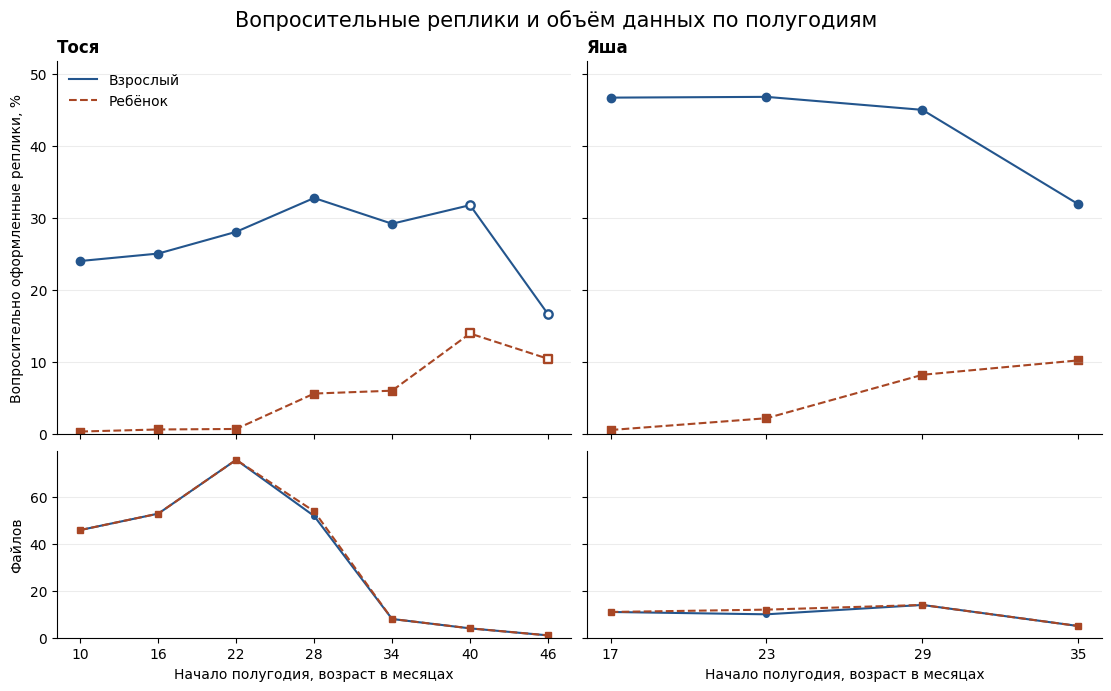

In [10]:
colors = {"взрослый": "#23558D", "ребёнок": "#A84624"}
markers = {"взрослый": "o", "ребёнок": "s"}
fig, axes = plt.subplots(
    2, 2, sharex="col", sharey="row", figsize=(11, 6.8),
    gridspec_kw={"height_ratios": [2, 1]}, layout="constrained",
)
for column, child in enumerate(SERIES.values()):
    top, bottom = axes[:, column]
    child_data = periods.loc[periods["child"] == child]
    for group in MAIN_GROUPS:
        part = child_data.loc[child_data["group"] == group].set_index("start")
        full_index = range(ANCHORS[child], int(child_data["start"].max()) + 1, HALF_YEAR)
        part = part.reindex(full_index)
        color, marker = colors[group], markers[group]
        top.plot(part.index, part["pct"], color=color, label=group.capitalize(),
                 linestyle="-" if group == "взрослый" else "--")
        regular = part["files"].ge(5)
        thin = part["files"].lt(5)
        top.scatter(part.index[regular], part.loc[regular, "pct"], color=color, marker=marker)
        top.scatter(part.index[thin], part.loc[thin, "pct"], facecolors="white",
                    edgecolors=color, marker=marker, linewidths=1.7, zorder=4)
        bottom.plot(part.index, part["files"], color=color, marker=marker,
                    linestyle="-" if group == "взрослый" else "--", markersize=4)
    top.set_title(child, loc="left", fontweight="bold")
    top.set_ylim(0, max(50, 5 + periods["pct"].max()))
    bottom.set_ylim(bottom=0)
    bottom.set_xlabel("Начало полугодия, возраст в месяцах")
    bottom.set_xticks(sorted(child_data["start"].unique()))
    for ax in (top, bottom):
        ax.grid(axis="y", alpha=0.24)
        ax.spines[["top", "right"]].set_visible(False)

axes[0, 0].set_ylabel("Вопросительно оформленные реплики, %")
axes[1, 0].set_ylabel("Файлов")
axes[0, 0].legend(loc="upper left", frameon=False)
fig.suptitle("Вопросительные реплики и объём данных по полугодиям", fontsize=15)
plt.show()

## 7. Проверки устойчивости

Меняем одно правило за раз и пересчитываем доли. Это показывает чувствительность к определению вопроса, составу говорящих и весу больших транскрипций.

1. Учитываем только обычный конечный `?`.
2. Убираем строки, состоящие только из условных обозначений.
3. Добавляем роли `Female` и `Relative` к взрослым.
4. Считаем у взрослых только родителей. У Тоси это существенно меняет состав выборки, поскольку в основной группе преобладает речь няни.
5. Усредняем доли по файлам с одинаковым весом внутри роли и полугодия. Реплики внутри файла зависимы; несколько файлов могут относиться к одной дате.
6. Проверяем, что два предположительно ошибочно записанных возраста согласуются с соседними файлами, и временно восстанавливаем их. У двух остальных пропусков возраст в этой проверке оставляем неизвестным.

В таблице приведена средняя по полугодиям абсолютная разница с основным расчётом и максимальная разница. Пороговых решений о значимости здесь нет.

In [11]:
extra_adults = utterances.loc[
    utterances["months"].notna() & utterances["role"].isin(UNCERTAIN_ROLES)
].assign(group="взрослый")
parents_only = eligible.loc[eligible["group"].eq("ребёнок") | eligible["role"].isin(PARENT_ROLES)]

per_file = assign_periods(eligible, ANCHORS).groupby(
    ["child", "start", "group", "file"], as_index=False,
).agg(total=("line", "size"), questions=("question", "sum"))
per_file["pct"] = 100 * per_file["questions"] / per_file["total"]
equal_file_weights = per_file.groupby(["child", "start", "group"], as_index=False)["pct"].mean()

indexed_files = files.set_index("file")
t100, t101 = [indexed_files.loc[f"Tosya/T{n}.cha"] for n in (100, 101)]
assert t100["date"] == t101["date"] and t100["date"]
assert t101["other_ages"] == "GRA: " + t100["age"]
neighbors = indexed_files.loc[["Tosya/T200.cha", "Tosya/T201.cha", "Tosya/T203.cha"], "age"]
assert neighbors.nunique() == 1
assert indexed_files.loc["Tosya/T202.cha", "other_ages"] == "NAN: " + neighbors.iloc[0]
candidate_ages = {"Tosya/T101.cha": t100["age"], "Tosya/T202.cha": neighbors.iloc[0]}
extra_age = utterances.loc[
    utterances["file"].isin(candidate_ages) & utterances["group"].isin(MAIN_GROUPS)
].copy()
assert extra_age["months"].isna().all()
extra_age["age"] = extra_age["file"].map(candidate_ages)
extra_age["months"] = extra_age["age"].map(lambda value: age_components(value)[0])

variants = {
    "Только обычный конечный ?": summarize_periods(eligible, flag="plain_final"),
    "Без строк-заполнителей": summarize_periods(eligible.loc[~eligible["placeholder"]]),
    "Расширенная группа взрослых": summarize_periods(pd.concat([eligible, extra_adults])),
    "Взрослые представлены только родителями": summarize_periods(parents_only),
    "Одинаковый вес файлов": equal_file_weights,
    "Два восстановленных возраста": summarize_periods(pd.concat([eligible, extra_age])),
}
comparison_keys = ["child", "start", "group"]
baseline_pct = periods.set_index(comparison_keys)["pct"]
variant_rows = []
for name, table in variants.items():
    alternative_pct = table.set_index(comparison_keys)["pct"]
    abs_difference = alternative_pct.sub(baseline_pct).abs()
    for (child, group), range_of_differences in abs_difference.groupby(level=["child", "group"]):
        variant_rows.append({
            "Вариант": name, "Серия": child, "Группа": group,
            "Сопоставимых полугодий": range_of_differences.count(),
            "Средняя разница, п. п.": range_of_differences.mean(),
            "Макс. разница, п. п.": range_of_differences.max(),
        })
sensitivity = pd.DataFrame(variant_rows)
display(sensitivity.round(2))

,Вариант,Серия,Группа,Сопоставимых полугодий,"Средняя разница, п. п.","Макс. разница, п. п."
0,Только обычный конечный ?,Тося,взрослый,7,0.11,0.32
1,Только обычный конечный ?,Тося,ребёнок,7,0.09,0.59
2,Только обычный конечный ?,Яша,взрослый,4,0.57,0.85
3,Только обычный конечный ?,Яша,ребёнок,4,0.01,0.02
4,Без строк-заполнителей,Тося,взрослый,7,0.10,0.23
5,Без строк-заполнителей,Тося,ребёнок,7,0.02,0.15
6,Без строк-заполнителей,Яша,взрослый,4,0.20,0.55
7,Без строк-заполнителей,Яша,ребёнок,4,0.05,0.16
8,Расширенная группа взрослых,Тося,взрослый,7,0.03,0.10
9,Расширенная группа взрослых,Тося,ребёнок,7,0.00,0.00


### Сопоставление на одинаковых возрастных границах

Серии начинаются в разном возрасте. Чтобы сравнить их в одних и тех же возрастных окнах, перестраиваем сетку с границами, кратными шести месяцам. Берём три окна, целиком лежащие между минимальным и максимальным наблюдаемыми возрастами обеих серий. Это проверка сетки интервалов; распределение записей и состав взрослых по-прежнему различаются.

In [12]:
common_start, common_end = 18, 36
common_grid = summarize_periods(eligible, anchors={"Тося": 0, "Яша": 0})
common_grid = common_grid.loc[common_grid["start"].between(common_start, common_end - HALF_YEAR)]
common_view = common_grid.pivot(index="start", columns=["child", "group"], values="pct")
common_view = common_view.reindex(
    columns=pd.MultiIndex.from_product([list(SERIES.values()), MAIN_GROUPS]),
)
common_view.index = [f"[{start}, {start + HALF_YEAR})" for start in common_view.index]
common_view.index.name = "Возраст, мес."
display(common_view.round(2))

Тося              Яша        
              взрослый ребёнок взрослый ребёнок
Возраст, мес.                                  
[18, 24)         27.56    0.62    47.12    1.23
[24, 30)         27.41    1.14    47.44    2.40
[30, 36)         31.82    7.34    41.18   10.08

## 8. Величина изменений и вывод

В следующей ячейке по каждой кривой сравниваются первое, предпоследнее и последнее полугодия. Это показывает, насколько вывод о росте или снижении зависит от крайней точки. `start` используется только для упорядочивания, а разности считаются по неокруглённым долям.

In [13]:
endpoint_rows = []
for (child, group), curve in periods.groupby(["child", "group"], sort=False):
    first, prior, last = [curve.sort_values("start").iloc[index] for index in (0, -2, -1)]
    endpoint_rows.append({
        "Серия": child, "Группа": group,
        "Первое полугодие, %": first["pct"],
        "Предпоследнее, %": prior["pct"],
        "Последнее, %": last["pct"],
        "Δ до предпоследнего, п. п.": prior["pct"] - first["pct"],
        "Δ до последнего, п. п.": last["pct"] - first["pct"],
    })
endpoints = pd.DataFrame(endpoint_rows)
display(endpoints.round(2))

,Серия,Группа,"Первое полугодие, %","Предпоследнее, %","Последнее, %","Δ до предпоследнего, п. п.","Δ до последнего, п. п."
0,Тося,взрослый,24.03,31.78,16.67,7.75,-7.37
1,Тося,ребёнок,0.37,13.97,10.47,13.60,10.10
2,Яша,взрослый,46.70,45.00,31.91,-1.70,-14.79
3,Яша,ребёнок,0.58,8.24,10.24,7.66,9.66


### Что меняется, если сделать у Тоси ровно шесть интервалов

Здесь объединяем группу `[40, 46)` и запись в точке `3;10.00`, чтобы получить последний интервал `[40, 46]` с включённой правой границей. Сначала складываем числа реплик и вопросов по группам, затем делим суммы. Доли двух интервалов нельзя усреднять напрямую из-за разных объёмов.

In [14]:
last_tosya = periods.loc[(periods["child"] == "Тося") & periods["start"].ge(40)]
last_six_bins = last_tosya.groupby("group", as_index=False)[
    ["total", "questions", "files"]
].sum()
last_six_bins["pct"] = 100 * last_six_bins["questions"] / last_six_bins["total"]
last_six_bins["interval"] = "[40, 46]"
display(last_six_bins.round(2).rename(columns=TABLE_LABELS))

,Группа,Реплик,Вопросительных,Файлов с репликами группы,"Доля, %","Возраст, мес."
0,взрослый,153,45,5,29.41,"[40, 46]"
1,ребёнок,315,41,5,13.02,"[40, 46]"


### Ответ на исследовательский вопрос

**В обеих сериях в поздних полугодиях сами дети задают больше вопросов в пересчёте на 100 реплик.** У Тоси доля держится ниже 1% в первые три окна, а в [28, 34) мес. достигает 5,64%. Она доходит до 13,97% в [40, 46) мес., а последняя точка в 46 месяцев даёт 10,47% по одному файлу. При шести интервалах, когда этот файл включён в предыдущее полугодие, итоговая доля составляет 13,02%. У Яши доля растёт во всех четырёх наблюдаемых окнах с 0,58% до 10,24%. Рост у обоих виден и на общей сетке с 18 до 36 месяцев.

**Взрослые задают вопросы чаще детей во всех наблюдаемых полугодиях, но кривые взрослых различаются между сериями.** У Тоси доля взрослой речи с вопросительным знаком растёт с 24,03% до 32,78% к [28, 34) мес., затем колеблется. На последней точке снижение до 16,67% опирается на четыре вопроса среди 24 реплик взрослых одного файла. У Яши в первых трёх окнах доля находится в диапазоне 45,00–46,81%, а в последнем падает до 31,91% по пяти файлам. В общей возрастной сетке [18, 36) видны разные направления в позднем окне. Единого возрастного рисунка для взрослых в этих двух сериях нет.

**Состав взрослых важен для интерпретации.** У Тоси 83,53% реплик взрослых приходится на роль `Nurse`, а у Яши 94,76% — на отца. Если оставить только родителей, доля у взрослых в отдельных полугодиях Тоси меняется до 10,62 п. п. Одинаковый вес файлов меняет отдельные оценки до 5,46 п. п. Правило для конечного знака, исключение строк-заполнителей, расширение категории взрослых и два предположительно восстановленных возраста меняют отдельные доли менее чем на 1 п. п.

**Объём зависит от правила отбора.** В ZIP есть 42 550 реплик участников с явными взрослыми ролями, из них 41 967 вошли в возрастной анализ. Число 48 028 получается при подсчёте всех реплик за вычетом речи Тоси и Яши, включая 5 237 реплик других детей. Это возможное объяснение оценки «около 48 тыс.», упомянутой в задании. Приведённые там 53 089 реплик взрослых по этому ZIP и нашему правилу не воспроизводятся. Без версии данных и правил подсчёта, использованных для той цифры, установить точную причину расхождения нельзя.

### Границы интерпретации

Результат описывает две лонгитюдные серии. Возраст, состав участников, занятия во время записи и полнота материала могут меняться одновременно. Реплики из одной записи зависимы, а отдельные файлы могут относиться к одной дате. Поэтому доли и разности приведены как описательные оценки без теста, который считал бы все реплики независимыми. Обозначение `?` отражает пунктуацию транскрипции. Адресат взрослой реплики и её педагогическая или информационная функция в этот показатель не входят. Результат статьи о функциональном составе вопросов остаётся теоретическим контекстом для проекта.